# Figure 3 (main text) — what the model reconstructs about resistance evolution

In [1]:
import json
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import PathPatch, Patch, Rectangle
from matplotlib.path import Path as MplPath

SMALL = 6.0  # minimum annotation size anywhere in the figure

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7.5,
    "xtick.labelsize": 6.5,
    "ytick.labelsize": 6.5,
    "legend.fontsize": 6.5,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 400,
    "figure.dpi": 140,
})

# Colours and method labels are imported, not copied, so Figure 3 cannot drift away from the
# analysis module every other panel of this project is drawn with.
# evostate paths: data in data/manuscript, analysis code in notebooks/manuscript/lib,
# figures written to results/rendered/manuscript.
REPO = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'data/manuscript').is_dir() and (p / 'notebooks/manuscript/lib').is_dir()), None)
if REPO is None:
    raise FileNotFoundError('Start Jupyter inside the evostate repository.')
MANUSCRIPT_DATA = REPO / 'data/manuscript'
MANUSCRIPT_LIB = REPO / 'notebooks/manuscript/lib'
RENDERED = REPO / 'results/rendered/manuscript'
ANALYSIS_DIR = str(MANUSCRIPT_LIB / "analysis_repr_evo")
if ANALYSIS_DIR not in sys.path:
    sys.path.insert(0, ANALYSIS_DIR)
from paper_figure_tb import CLASS_COLORS, CLASS_ORDER, METHOD_LABELS  # noqa: E402

print("matplotlib", mpl.__version__, "| classes:", len(CLASS_COLORS))


matplotlib 3.9.2 | classes: 9


## 1. Configuration — the cached artefacts that back each panel

In [2]:
BASE = MANUSCRIPT_DATA / "results_repr_evo"
SRC = BASE / "tuberculosis_genes19" / "figures_paper"
OUT = RENDERED / "figure3"
OUT.mkdir(parents=True, exist_ok=True)

# Panel b keeps the source notebook's order: the external method first, ours second.
MODEL_ORDER = ["HT_second-order", "TS_pretrained"]
DISPLAY_LABEL = {"HT_second-order": "HyperTraPS", "TS_pretrained": "EvoState"}

MIN_SUPPORT = 15   # gain events below which a feature is faded in panel a
ANNOTATE_N = 4     # worst-residual features labelled in panel b
MIN_FLOW = 0.01    # ribbons below this probability are dropped in panel c
DEP_COLORS = {"model": "#1f6fb4", "empirical": "#8c8c8c"}

FILES = {
    "hierarchy": SRC / "panelB_empirical_hierarchy.csv",
    "scatter": SRC / "panelC_ordering_scatter.csv",
    "bootstrap": SRC / "panelC_bootstrap_summary.csv",
    "composition": SRC / "panelD_step_composition.csv",
    "flows": SRC / "panelD_flows.csv",
    "dependencies": SRC / "panelE_dependencies.csv",
}
for name, path in FILES.items():
    assert path.exists(), f"missing {name}: {path}"
print("all source files resolved; output ->", OUT)


all source files resolved; output -> /apdcephfs_qy3/share_2932069/ziyiyang/1-antibiotic_resistance/EvoAMR/evoamr/evostate/results/rendered/manuscript/figure3


## 2. Load the cached artefacts

In [3]:
ORDER_EMP = pd.read_csv(FILES["hierarchy"])
SCATTER_C = pd.read_csv(FILES["scatter"])
BOOT = pd.read_csv(FILES["bootstrap"])
COMP_D = pd.read_csv(FILES["composition"], index_col=0)
FLOWS_D = pd.read_csv(FILES["flows"])

# Panel d keeps only the pairs the source analysis marked `selected`: model and empirical agree
# in direction, both arms clear the support threshold, and Fisher's exact test is significant.
DEP = pd.read_csv(FILES["dependencies"])
DEP_SEL = DEP[DEP["selected"].astype(bool)].sort_values("model_log2_shift").reset_index(drop=True)

# class / mechanism per feature come straight from the hierarchy table
CLASS_MAP = dict(zip(ORDER_EMP["feature"].astype(str), ORDER_EMP["class"].astype(str)))
MECH_MAP = dict(zip(ORDER_EMP["feature"].astype(str), ORDER_EMP["mechanism"].astype(str)))
PALETTE = {f: CLASS_COLORS.get(c, "#999999") for f, c in CLASS_MAP.items()}

# Panel b statistics: cluster bootstrap is the reported resampling scheme
CLUSTER = BOOT[BOOT["resampling"] == "cluster"]
RECOVERY, CI_TEXT = {}, {}
for name in MODEL_ORDER:
    rows = CLUSTER[CLUSTER["model"] == name]
    RECOVERY[name] = {q: float(rows.loc[rows["quantity"] == q, "point_estimate"].iloc[0])
                      for q in ("spearman", "mae") if (rows["quantity"] == q).any()}
    rho = rows[rows["quantity"] == "spearman"]
    if len(rho):
        r = rho.iloc[0]
        CI_TEXT[name] = "95%% CI [%.3f, %.3f]" % (r["ci_lo"], r["ci_hi"])

print("features:", len(ORDER_EMP), "| low support (<%d gains): %d"
      % (MIN_SUPPORT, int((ORDER_EMP["n_gain_events"] < MIN_SUPPORT).sum())))
print("recovery:", {k: {m: round(v, 3) for m, v in s.items()} for k, s in RECOVERY.items()})
print("CI:", CI_TEXT)
print("trajectory steps:", list(COMP_D.index), "| flows:", len(FLOWS_D))
print("dependency pairs: %d candidates -> %d selected" % (len(DEP), len(DEP_SEL)))
DEP_SEL[["pair", "effect", "model_log2_shift", "emp_log2_or", "fisher_p"]].round(3)


features: 19 | low support (<15 gains): 6
recovery: {'HT_second-order': {'spearman': 0.76, 'mae': 1.351}, 'TS_pretrained': {'spearman': 0.788, 'mae': 1.083}}
CI: {'HT_second-order': '95% CI [0.607, 0.830]', 'TS_pretrained': '95% CI [0.626, 0.890]'}
trajectory steps: ['step1', 'step2', 'step3', 'step4'] | flows: 238
dependency pairs: 80 candidates -> 6 selected


,pair,effect,model_log2_shift,emp_log2_or,fisher_p
0,rpsL → rrs_str,represses,-6.507,-6.375,0.000
1,rrs_str → rpsL,represses,-5.534,-6.559,0.000
2,rrs_str → PembA,promotes,1.879,2.196,0.006
3,rrs_str → gyrB,promotes,1.902,2.957,0.001
4,rrs_str → gyrA,promotes,1.961,1.351,0.005
5,rrs_str → pncA,promotes,2.369,1.718,0.002


## 3. Shared helpers

In [4]:
def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(length=2.4, pad=1.6)


def panel_letter(ax, letter, dx=-30, dy=6):
    ax.annotate(letter, xy=(0, 1), xycoords="axes fraction", xytext=(dx, dy),
                textcoords="offset points", ha="left", va="bottom",
                fontsize=9, fontweight="bold")


def classes_present():
    """Classes actually drawn, in the canonical order, for one shared legend."""
    used = set(CLASS_MAP.values()) | {c for c in COMP_D.columns if COMP_D[c].sum() > 0}
    return [c for c in CLASS_ORDER if c in used] + sorted(used - set(CLASS_ORDER))


print("classes in figure:", classes_present())


classes in figure: ['INH', 'RIF', 'STR', 'EMB', 'ETH', 'RIF-comp', 'PZA', 'INJ', 'FQ']


## 4. Figure 3

In [5]:
def draw_hierarchy(ax, letter):
    """Panel a: empirical acquisition hierarchy as a lollipop, ordered earliest to latest.

    Marker area scales with the number of observed gain events; triangles mark compensatory
    mutations, which do not confer resistance themselves; features with fewer than MIN_SUPPORT
    gain events are faded because their expected order is poorly determined.
    """
    d = ORDER_EMP.sort_values("expected_order").reset_index(drop=True)
    y = np.arange(len(d))[::-1]
    for yi, (_, r) in zip(y, d.iterrows()):
        f = str(r["feature"])
        col = CLASS_COLORS.get(CLASS_MAP.get(f, "other"), "#999999")
        alpha = 0.35 if int(r["n_gain_events"]) < MIN_SUPPORT else 1.0
        ax.hlines(yi, 0.6, r["expected_order"], color=col, alpha=alpha * 0.55, lw=0.9)
        ax.errorbar(r["expected_order"], yi, xerr=r["order_sd"], fmt="none", ecolor=col,
                    alpha=alpha * 0.7, elinewidth=0.6, capsize=1.2, capthick=0.6)
        ax.scatter(r["expected_order"], yi, s=5 + 0.85 * float(r["n_gain_events"]),
                   marker="^" if MECH_MAP.get(f) == "compensatory_mutation" else "o",
                   color=col, alpha=alpha, edgecolors="white", linewidths=0.4, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels([str(f) for f in d["feature"]], fontsize=5.8)
    for tick, f in zip(ax.get_yticklabels(), d["feature"]):
        tick.set_color(CLASS_COLORS.get(CLASS_MAP.get(str(f), "other"), "#333333"))
    ax.set_ylim(-0.8, len(d) - 0.2)
    ax.set_xlim(0.4, float(np.nanmax(d["expected_order"] + d["order_sd"])) + 0.6)
    ax.set_xlabel("Empirical expected acquisition order\n(earlier $\\leftarrow$   $\\rightarrow$ later)")
    ax.set_title("Resistance acquisition hierarchy", pad=5)
    ax.text(0.985, 0.985, "marker size $\\propto$ gain events\n$\\blacktriangle$ compensatory\n"
                         "faded: <%d gains" % MIN_SUPPORT,
            transform=ax.transAxes, ha="right", va="top", fontsize=SMALL,
            color="#666666", linespacing=1.25)
    style(ax)
    panel_letter(ax, letter, dx=-40)


def draw_recovery(axes, letter):
    """Panel b: how closely each model's expected order tracks the empirical one.

    Shared axes and an identity line, so the comparison is the scatter about y = x; the four
    features with the largest absolute residual are labelled in each panel.
    """
    lo = float(np.nanmin([SCATTER_C["empirical_order"].min(), SCATTER_C["model_order"].min()])) - 0.4
    hi = float(np.nanmax([SCATTER_C["empirical_order"].max(), SCATTER_C["model_order"].max()])) + 0.4
    for ai, (ax, name) in enumerate(zip(axes, MODEL_ORDER)):
        sub = SCATTER_C[SCATTER_C["model"] == name]
        ax.plot([lo, hi], [lo, hi], "--", color="#999999", lw=0.7, zorder=1)
        ax.scatter(sub["empirical_order"], sub["model_order"], s=22, zorder=3,
                   c=[PALETTE.get(f, "#999999") for f in sub["feature"]],
                   edgecolors="white", linewidths=0.4)
        worst = sub.reindex(sub["residual"].abs().sort_values(ascending=False).index).head(ANNOTATE_N)
        for _, r in worst.iterrows():
            # flip the label inward near the right edge, otherwise it is clipped
            near_edge = r["empirical_order"] > lo + 0.78 * (hi - lo)
            ax.annotate(str(r["feature"]), (r["empirical_order"], r["model_order"]),
                        fontsize=SMALL + 0.4, xytext=(-3 if near_edge else 3, 2),
                        textcoords="offset points", color="#444444",
                        ha="right" if near_edge else "left")
        s = RECOVERY.get(name, {})
        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)
        ax.set_xlabel("Empirical expected order")
        ax.set_title("%s\n$\\rho$ = %.3f   MAE = %.2f\n%s"
                     % (DISPLAY_LABEL.get(name, METHOD_LABELS.get(name, name)),
                        s.get("spearman", np.nan), s.get("mae", np.nan),
                        CI_TEXT.get(name, "")), pad=4, fontsize=7)
        style(ax)
        if ai == 0:
            ax.set_ylabel("Model expected order")
            panel_letter(ax, letter, dx=-34)
        else:
            ax.set_yticklabels([])


def _ribbon(ax, x0, x1, y0a, y0b, y1a, y1b, color, alpha=0.45):
    xm = (x0 + x1) / 2.0
    verts = [(x0, y0a), (xm, y0a), (xm, y1a), (x1, y1a),
             (x1, y1b), (xm, y1b), (xm, y0b), (x0, y0b), (x0, y0a)]
    codes = [MplPath.MOVETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4,
             MplPath.LINETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4,
             MplPath.CLOSEPOLY]
    ax.add_patch(PathPatch(MplPath(verts, codes), facecolor=color, edgecolor="none", alpha=alpha))


def draw_alluvial(ax, letter, bar_w=0.20, gap=0.012):
    """Panel c: drug-class composition of each acquisition step, with the flows between them.

    Bars are the class composition at a given step over forward walks from the empty state;
    ribbons are the joint probability of consecutive class pairs.
    """
    steps = list(COMP_D.index)
    classes = [c for c in COMP_D.columns if COMP_D[c].sum() > 0]
    slot = {}
    for si, s in enumerate(steps):
        present = [c for c in classes if COMP_D.loc[s, c] > 1e-9]
        total = sum(COMP_D.loc[s, c] for c in present)
        y = 0.0
        scale = (1.0 - gap * max(0, len(present) - 1)) / max(total, 1e-12)
        for c in present:
            hgt = COMP_D.loc[s, c] * scale
            slot[(si, c)] = (y, y + hgt)
            ax.add_patch(Rectangle((si - bar_w / 2, y), bar_w, hgt,
                                   facecolor=CLASS_COLORS.get(c, "#999999"),
                                   edgecolor="white", linewidth=0.5))
            # Long class names do not fit across a bar, so they are set in two lines;
            # anything too thin to hold text is named by the leader labels on the right.
            if hgt > 0.075:
                ax.text(si, y + hgt / 2, c.replace("-", "-\n") if len(c) > 3 else c,
                        ha="center", va="center", fontsize=SMALL - 1.6,
                        color="white", fontweight="bold", linespacing=0.95)
            y += hgt + gap

    out_cur = {k: v[0] for k, v in slot.items()}
    in_cur = {k: v[0] for k, v in slot.items()}
    for si in range(len(steps) - 1):
        sub = FLOWS_D[FLOWS_D["step"] == si + 1].sort_values("prob", ascending=False)
        for _, r in sub.iterrows():
            if r["prob"] < MIN_FLOW:
                continue
            ka, kb = (si, r["src"]), (si + 1, r["dst"])
            if ka not in slot or kb not in slot:
                continue
            ha = (slot[ka][1] - slot[ka][0]) * (r["prob"] / max(COMP_D.iat[si, COMP_D.columns.get_loc(r["src"])], 1e-12))
            hb = (slot[kb][1] - slot[kb][0]) * (r["prob"] / max(COMP_D.iat[si + 1, COMP_D.columns.get_loc(r["dst"])], 1e-12))
            y0a, y1a = out_cur[ka], in_cur[kb]
            _ribbon(ax, si + bar_w / 2, si + 1 - bar_w / 2, y0a, y0a + ha, y1a, y1a + hb,
                    CLASS_COLORS.get(r["src"], "#999999"))
            out_cur[ka] = y0a + ha
            in_cur[kb] = y1a + hb

    # Name every class present, including the thin ones, next to the last step. Centres are
    # nudged apart so that adjacent thin classes stay readable.
    last = len(steps) - 1
    tail = sorted(((sum(slot[(last, c)]) / 2.0, c) for c in classes if (last, c) in slot),
                  reverse=True)
    min_gap, placed = 0.042, []
    for yc, c in tail:
        if placed and placed[-1][0] - yc < min_gap:
            yc = placed[-1][0] - min_gap
        placed.append((yc, c))
    x_lab = last + bar_w / 2 + 0.10
    for yc, c in placed:
        y_true = sum(slot[(last, c)]) / 2.0
        ax.plot([last + bar_w / 2 + 0.01, x_lab - 0.02], [y_true, yc], lw=0.4,
                color=CLASS_COLORS.get(c, "#999999"), alpha=0.8, clip_on=False)
        ax.text(x_lab, yc, c, ha="left", va="center", fontsize=SMALL - 0.6,
                color=CLASS_COLORS.get(c, "#999999"))

    ax.set_xlim(-0.45, last + 0.92)
    ax.set_ylim(-0.02, 1.03)
    ax.set_xticks(range(len(steps)))
    ax.set_xticklabels([str(i + 1) for i in range(len(steps))])
    ax.set_xlabel("Acquisition step")
    ax.set_yticks([])
    ax.grid(False)
    for sp in ("left", "right", "top"):
        ax.spines[sp].set_visible(False)
    ax.tick_params(length=2.4, pad=1.6)
    ax.set_title("Drug-class acquisition trajectories\n(forward walks from the susceptible state)",
                 pad=5)
    panel_letter(ax, letter, dx=-30)


def draw_dependencies(ax, letter):
    """Panel d: conditional dependencies, model prediction against an independent empirical estimate.

    For each ordered pair j -> i the model bar is the log2 change in the next-step probability of
    i once j is present, and the empirical bar is the log2 odds ratio of gaining i with versus
    without j, computed directly from the transitions rather than from the model. Only pairs that
    agree in direction, clear the support threshold and are significant by Fisher's exact test are
    shown. Counts are gains with / without the context present.
    """
    d = DEP_SEL
    y = np.arange(len(d))
    h = 0.34
    ax.barh(y + h / 2, d["model_log2_shift"], height=h, color=DEP_COLORS["model"],
            edgecolor="none", zorder=2, label="Model")
    ax.barh(y - h / 2, d["emp_log2_or"], height=h, color=DEP_COLORS["empirical"],
            edgecolor="none", zorder=2, label="Empirical ($\\log_2$ OR)")
    ax.axvline(0, color="#333333", lw=0.6, zorder=3)

    lim = float(np.nanmax(np.abs(np.concatenate([d["model_log2_shift"].values,
                                                 d["emp_log2_or"].values])))) * 1.42
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-0.7, len(d) - 0.3)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{p}*" if float(q) < 0.05 else str(p)
                        for p, q in zip(d["pair"], d["fisher_p"])], fontsize=6.0)
    for yi, (_, r) in zip(y, d.iterrows()):
        # counts go on the empty side of the axis so they never sit on top of a bar
        promotes = float(r["model_log2_shift"]) > 0
        ax.text(-lim * 0.96 if promotes else lim * 0.96, yi,
                "%d/%d gains" % (int(r["n_gain_ctx_present"]), int(r["n_gain_ctx_absent"])),
                fontsize=SMALL - 0.4, va="center",
                ha="left" if promotes else "right", color="#666666")
    ax.set_xlabel("$\\log_2$ change in next-step probability\nof $i$ given context $j$")
    ax.set_title("Conditional dependencies $j \\rightarrow i$\n"
                 "(model vs independent empirical estimate)", pad=5)
    ax.legend(frameon=False, loc="lower right", fontsize=SMALL + 0.3,
              handlelength=1.1, handletextpad=0.4, borderpad=0.2)
    style(ax)
    panel_letter(ax, letter, dx=-52)


a / b / c frames aligned at x = 0.1
Figure 3 written (a hierarchy | b ordering recovery | c class trajectories)


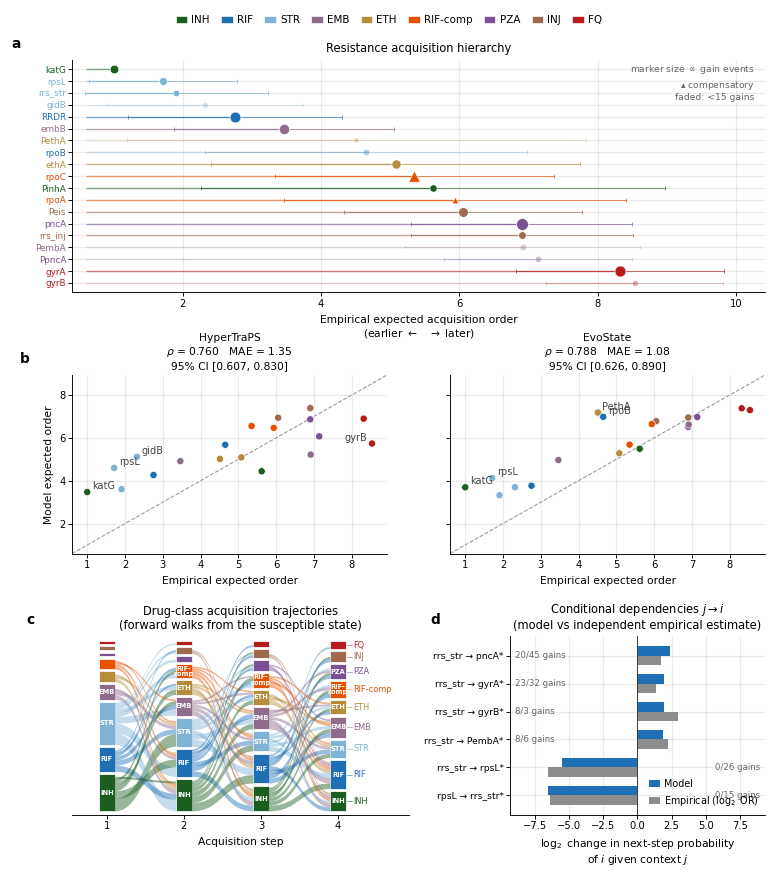

In [6]:
fig = plt.figure(figsize=(7.20, 7.80))
gs = fig.add_gridspec(3, 2, width_ratios=[1.32, 1.00], height_ratios=[1.12, 0.86, 0.86],
                      left=0.100, right=0.975, top=0.935, bottom=0.055,
                      wspace=0.34, hspace=0.42)

# a spans the full width
ax_a = fig.add_subplot(gs[0, :])
draw_hierarchy(ax_a, "a")

# b spans the full width too, but the two scatters keep a 1:1 aspect, so they are inset
# rather than stretched: the outer ratios are padding, not axes.
gs_b = gs[1, :].subgridspec(1, 2, wspace=0.20)
draw_recovery([fig.add_subplot(gs_b[0, 0]), fig.add_subplot(gs_b[0, 1])], "b")

ax_c = fig.add_subplot(gs[2, 0])
draw_alluvial(ax_c, "c")
ax_d = fig.add_subplot(gs[2, 1])
draw_dependencies(ax_d, "d")

# a, b and c must line up on one vertical: all three axes frames start at the gridspec left.
fig.canvas.draw()
_left = {k: round(float(ax.get_position().x0), 4)
         for k, ax in (("a", ax_a), ("b", fig.axes[1]), ("c", ax_c))}
assert len(set(_left.values())) == 1, f"panel frames are not aligned: {_left}"
print("a / b / c frames aligned at x =", _left["a"])

handles = [Patch(facecolor=CLASS_COLORS.get(c, "#999999"), edgecolor="white", linewidth=0.4, label=c)
           for c in classes_present()]
fig.legend(handles=handles, ncol=len(handles), frameon=False, loc="upper center",
           bbox_to_anchor=(0.5, 0.998), columnspacing=1.1, handlelength=1.1,
           handletextpad=0.4, fontsize=6.8)

fig.savefig(OUT / "figure3.pdf", bbox_inches="tight")
fig.savefig(OUT / "figure3.png", bbox_inches="tight", dpi=300)
print("Figure 3 written (a hierarchy | b ordering recovery | c class trajectories)")
plt.show()


## 5. Source data

In [7]:
# Copy the exact inputs next to the figure so the display item is self-contained.
written = []
for name, path in FILES.items():
    dest = OUT / f"figure3_source_data_{name}.csv"
    dest.write_bytes(path.read_bytes())
    written.append(dest.name)

pd.DataFrame([
    dict(panel="a", quantity="features", value=len(ORDER_EMP)),
    dict(panel="a", quantity="low-support features", value=int((ORDER_EMP["n_gain_events"] < MIN_SUPPORT).sum())),
    dict(panel="b", quantity="rho HyperTraPS", value=round(RECOVERY["HT_second-order"]["spearman"], 3)),
    dict(panel="b", quantity="rho EvoState", value=round(RECOVERY["TS_pretrained"]["spearman"], 3)),
    dict(panel="b", quantity="MAE HyperTraPS", value=round(RECOVERY["HT_second-order"]["mae"], 3)),
    dict(panel="b", quantity="MAE EvoState", value=round(RECOVERY["TS_pretrained"]["mae"], 3)),
    dict(panel="c", quantity="steps", value=len(COMP_D)),
    dict(panel="c", quantity="ribbons above min_flow", value=int((FLOWS_D["prob"] >= MIN_FLOW).sum())),
    dict(panel="d", quantity="candidate pairs", value=len(DEP)),
    dict(panel="d", quantity="selected pairs", value=len(DEP_SEL)),
    dict(panel="d", quantity="promoting pairs", value=int((DEP_SEL["model_log2_shift"] > 0).sum())),
    dict(panel="d", quantity="repressing pairs", value=int((DEP_SEL["model_log2_shift"] < 0).sum())),
]).to_csv(OUT / "figure3_quotable_numbers.csv", index=False)

print("source data written:", sorted(written))
pd.read_csv(OUT / "figure3_quotable_numbers.csv")


source data written: ['figure3_source_data_bootstrap.csv', 'figure3_source_data_composition.csv', 'figure3_source_data_dependencies.csv', 'figure3_source_data_flows.csv', 'figure3_source_data_hierarchy.csv', 'figure3_source_data_scatter.csv']


,panel,quantity,value
0,a,features,19.000
1,a,low-support features,6.000
2,b,rho HyperTraPS,0.760
3,b,rho EvoState,0.788
4,b,MAE HyperTraPS,1.351
5,b,MAE EvoState,1.083
6,c,steps,4.000
7,c,ribbons above min_flow,109.000
8,d,candidate pairs,80.000
9,d,selected pairs,6.000
